# Project 1: Friends Scripts: Joey Tribbiani
**Text Mining (G00C8A & G00C8B)**

**Character analysed:** Joey Tribbiani  
**Data:** `friends.csv`, the scripts of the Friends seasons (columns `Text`, `Speaker`, `Episode`, `Season`, `Show`).

1. imports the libraries 
2. downloads the NLTK data that is needed (stopwords and the Punkt sentence/word tokeniser)
3. creates the Porter stemmer and the NLTK stopword list
4. reads `friends.csv`
5. defines `name_alias_map`: nicknames and surnames are mapped to one name (rach → rachel) so that variants of a name are counted as the same person
6. defines `contractions_dict`: slang and contractions are mapped to full words (gonna → going to) so that tokenisation does not break them 
7. defines `spoken_fillers`: list of interjections and generic words (hey, yeah, know, like) are added to the NLTK stopwords as `custom_stopwords`. This is a subjective choice and it is used only in Q3 and Q4, not in Q1 or Q2, where every spoken word or noun counts
8. helper functions:
   - `strip_stage_directions`: removes text in `( )` and `[ ]` and collapses whitespace
   - `expand_contractions`: lower-cases, normalises curly quotes, expands contractions and repairs dropped g's (walkin' → walking)
   - `stem_to_lexeme_mapper`: maps each Porter stem back to its most frequent original word so tables and clouds show readable words

In [2]:
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import sent_tokenize, word_tokenize

import spacy
import seaborn as sns

for resource in ["stopwords", "punkt", "punkt_tab"]:
    nltk.download(resource, quiet=True)

stemmer = PorterStemmer()
nltk_stopwords = set(stopwords.words("english"))

df_raw = pd.read_csv("friends.csv")

# alias mapping since the same person could have different variations of their name
name_alias_map = {
    "rach": "rachel",
    "pheebs": "phoebe","phoebs": "phoebe",
    "chan": "chandler", "bing": "chandler",
    "mon": "monica",
    "joe": "joey", "joseph": "joey","tribbiani": "joey","joey tribbiani":"joey"}

# dialogue  mapping so conversational slang is not misinterpreted
contractions_dict = {
    r"\bc'mon\b": "come on", r"\bgonna\b": "going to", r"\bwanna\b": "want to",
    r"\bdunno\b": "do not know", r"\bgotta\b": "got to",    r"\bain't\b": "is not", r"\bdon't\b": "do not", r"\bdoesn't\b": "does not",
    r"\bdidn't\b": "did not", r"\bcan't\b": "cannot", r"\bwon't\b": "will not",
    r"\bisn't\b": "is not", r"\baren't\b": "are not", r"\bcouldn't\b": "could not",
    r"\bwouldn't\b": "would not", r"\bshouldn't\b": "should not", r"\bi'm\b": "i am",
    r"\byou're\b": "you are", r"\bhe's\b": "he is", r"\bshe's\b": "she is",
    r"\bit's\b": "it is", r"\bwe're\b": "we are", r"\bthey're\b": "they are",r"(?<!\w)'em\b": "them",
    r"\bthere's\b": "there is", r"\bthat's\b": "that is", r"\bwhat's\b": "what is", r"\bwho's\b": "who is"}

#  fillers and dialogue noise stopwords
spoken_fillers = {"hey", "yeah", "know", "oh", "ohh", "look", "right", "like", "get", "okay", "go",
    "well", "na", "uh", "got", "ok", "gon", "wan", "think", "mean", "say", "see", "ya", "x",
    "come", "going", "want", "thing", "things", "something", "us", "would", "could", "s",
    "take", "tell", "make", "let", "uhh", "yeahs", "ooh", "ah", "huh", "hi", "yes", "nah",
    "umm", "uhm", "woah", "alright", "somethin", "dunno", "naa", "noooo", "hmm", "e",
    "dude", "man", "guys", "guy", "one", "really", "back", "said", "y'know"}

# add these also to the more general stopword list 
custom_stopwords = nltk_stopwords.union(spoken_fillers)

def strip_stage_directions(text):
    if not isinstance(text, str): return ""
    text = re.sub(r"\([^)]*\)", "", text)
    text = re.sub(r"\[[^\]]*\]", "", text)
    return re.sub(r"\s+", " ", text).strip()

def fix_dropped_g(t):
    return re.sub(r"\b(\w{2,})in'(?=\W|$)", r"\1ing", t)

def expand_contractions(text):
    t = str(text).lower().replace("’", "'").replace("‘", "'")
    for pattern, replacement in contractions_dict.items():
        t = re.sub(pattern, replacement, t)
    return fix_dropped_g(t)

def stem_to_lexeme_mapper(stemmed_tokens, original_tokens):
    mapping = defaultdict(Counter)
    for stem, orig in zip(stemmed_tokens, original_tokens): mapping[stem][orig.lower()] += 1
    stem2lexeme = {}
    for stem, counts in mapping.items(): stem2lexeme[stem] = counts.most_common(1)[0][0]
    return stem2lexeme

## Preprocessing

In [3]:
# data checks 
spk = df_raw["Speaker"].fillna("").str.strip()
print("where Joey is the speaker :", int((spk.str.lower() == "joey").sum()))
other = spk[spk.str.contains("joey", case=False) & (spk.str.lower() != "joey")]
print("labels that contain 'joey' but not his lines):", other.value_counts().head(8).to_dict())
print("episodes per season in the file:", df_raw.groupby("Season")["Episode"].nunique().to_dict(), "-> total", df_raw[["Season", "Episode"]].drop_duplicates().shape[0])

where Joey is the speaker : 8047
labels that contain 'joey' but not his lines): {'Chandler and Joey': 16, 'Joey and Chandler': 13, "Joey's Hand Twin": 13, 'Joey/Drake': 13, 'Joey and Ross': 10, "Joey's Co-Star": 6, 'CHANDLER and JOEY': 6, "Joey's Doctor": 6}
episodes per season in the file: {'Season-01': 24, 'Season-02': 23, 'Season-03': 25, 'Season-04': 23, 'Season-05': 23, 'Season-06': 23, 'Season-07': 23, 'Season-08': 23, 'Season-09': 23, 'Season-10': 15} -> total 225


**Data checks**
- Joey has 8,047 lines under the label `Joey`. Top 8 other labels that contain "joey" ("Joey's Hand Twin", "Joey/Drake") add up to only 83 lines (about 1% of 8,047), so **only the label `Joey` is used**.
- The CSV contains **225 episodes** (Season 10 only 15) so the dataset does not contain all of them

### Which preprocessing step where, and why
| Step | Q1 | Q2 | Q3 | Q4 |
|---|---|---|---|---|
| remove stage directions ( ) / [ ] | yes | yes | yes | yes |
| remove punctuation | no (needed to split sentences) | no (NER needs the original text) | yes (`isalpha`), after expanding contractions | yes (same tokens as Q3) |
| lower case | no | no (capital letters help NER) | yes | yes |
| sentence / word tokenisation | sentences: `sent_tokenize`; words: regex (keeps "don't" as one word) | spaCy tokenizer | `word_tokenize` | `word_tokenize` |
| slang / contraction expansion | no (one spoken word = one word) | no | yes | yes |
| alias mapping  | no | yes (person names) | yes | yes |
| stopwords | no (count everything spoken) | NLTK only (we count what he says, including colloquial nouns such as guy or man) | NLTK + fillers; tokens of 1–2 letters dropped | NLTK + fillers; tokens of 1–2 letters dropped |
| Porter stemming | no | no (spaCy lemma instead) | yes (merges want / wants / wanted; shown as the most frequent original word) | no (keep original words so pairs stay readable, e.g. lives–days) |
| POS tagging + NER | no | yes (nouns and `PERSON` entities) | no | no |

- **Q1 counts raw speech:** stopwords and punctuation are kept, because the question asks how much Joey *speaks*.
- **Q2 uses spaCy on the original text:** capitalisation and punctuation are the cues NER model rely on,
- **Q3 and Q4 are about content:** lower-casing, removing punctuation, stopwords and fillers, and (Q3) stemming reduce the vocabulary so frequent words do not dominate
- **Q4 is not stemmed** so that associated pairs remain readable words.

### Q1 - How many sentences and words does Joey speak per episode, and does this differ across seasons?

1. Strip stage directions and keep Joey's non-empty lines
2. Count words per line (regex) and sentences per line (`sent_tokenize`) and sum them per episode 
3. Mean, median and standard deviation overall, per season and aggregate words per line.
4. Kruskal–Wallis test across seasons for words and sentences per episode (non-parametric, no normality assumption), with effect size ε² = H / (n − 1)
5. Visualise via plots

Episodes: 225 | episodes without Joey lines: 0
        sents  words  lines
mean     66.5  382.3   35.7
std      31.3  174.7   14.7
median   60.0  348.0   33.0

            episodes  words  words_sd  sents  sents_sd  lines  words_per_line
Season                                                                      
Season-01        24  254.0     108.8   44.6      16.8   25.9             9.6
Season-02        23  314.3     139.5   46.9      21.1   28.4            11.5
Season-03        25  322.0     117.5   52.2      18.3   31.0            10.4
Season-04        23  361.8     159.1   63.9      28.3   35.6            10.3
Season-05        23  423.1     190.6   79.0      37.2   40.5            10.4
Season-06        23  478.0     182.0   82.0      32.2   39.5            12.5
Season-07        23  425.0     185.4   80.2      32.9   40.5            10.3
Season-08        23  467.6     228.2   82.7      37.8   39.6            11.8
Season-09        23  396.8     163.9   64.5      29.7   37.8         

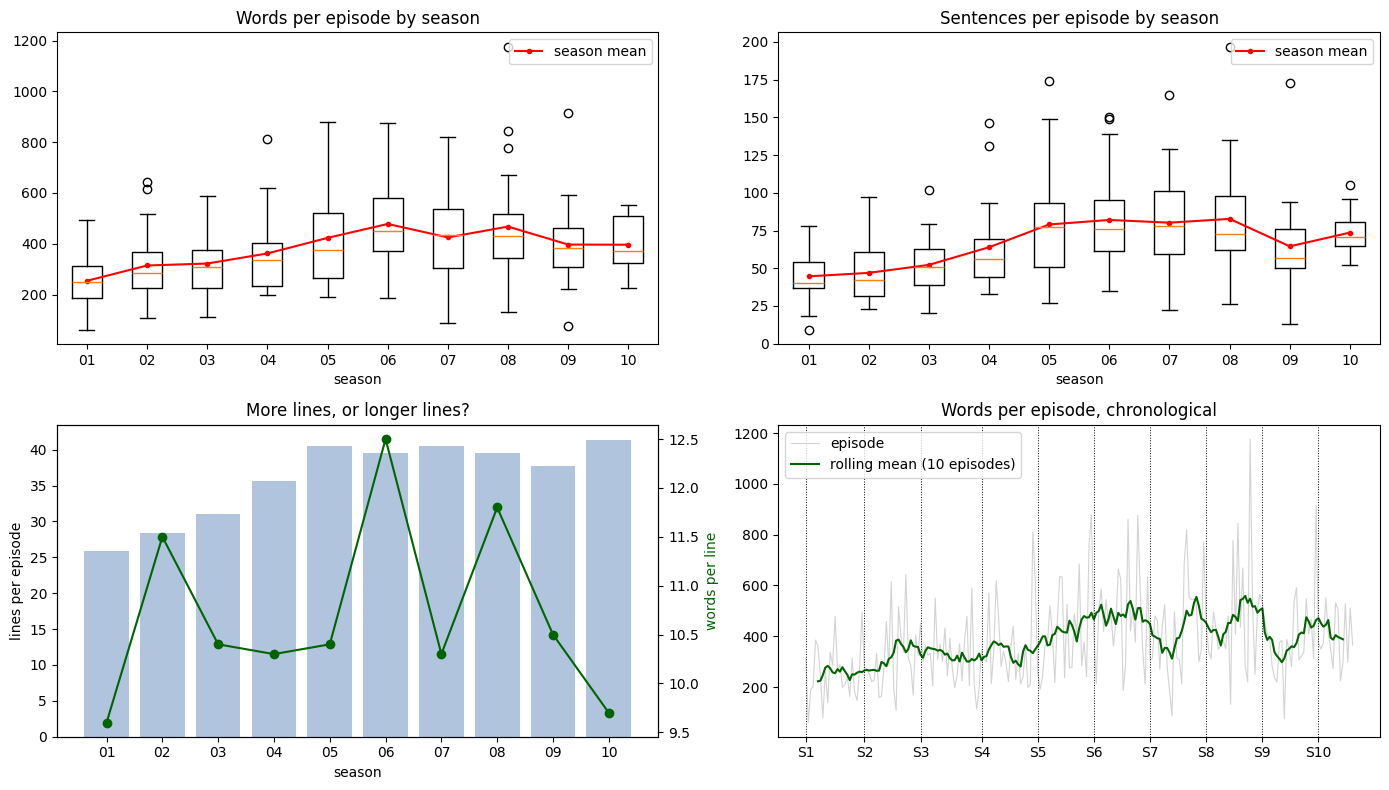

In [3]:
def count_words(text):
    return len(re.findall(r"[A-Za-z0-9]+(?:'[A-Za-z]+)*", str(text).replace("’", "'")))

def count_sents(text):
    return max(1, len(sent_tokenize(text))) if text else 0

q1 = df_raw.copy()
q1["clean_line"] = q1["Text"].apply(strip_stage_directions)                              
joey_lines = q1[q1["Speaker"].fillna("").str.strip().str.lower().eq("joey") & (q1["clean_line"] != "")].copy()
joey_lines["words"] = joey_lines["clean_line"].apply(count_words)
joey_lines["sents"] = joey_lines["clean_line"].apply(count_sents)

# one row per episode of the CSV; an episode without Joey lines would count as 0 
all_eps = q1[["Season", "Episode"]].drop_duplicates()
ep = (joey_lines.groupby(["Season", "Episode"]).agg(lines=("clean_line", "count"), sents=("sents", "sum"), words=("words", "sum")).reset_index().merge(all_eps, on=["Season", "Episode"], how="right").fillna(0))
ep["words_per_line"] = ep["words"] / ep["lines"].replace(0, np.nan)
ep["season_num"] = ep["Season"].str.extract(r"(\d+)")[0].astype(int)
ep["ep_num"] = ep["Episode"].str.extract(r"(\d+)")[0].astype(int)
ep = ep.sort_values(["season_num", "ep_num"]).reset_index(drop=True)

print(f"Episodes: {len(ep)} | episodes without Joey lines: {(ep.lines == 0).sum()}")
print(ep[["sents", "words", "lines"]].agg(["mean", "std", "median"]).round(1).to_string())
season = ep.groupby("Season").agg(episodes=("Episode", "count"), words=("words", "mean"), words_sd=("words", "std"),sents=("sents", "mean"), sents_sd=("sents", "std"), lines=("lines", "mean"),words_per_line=("words_per_line", "mean")).round(1)
print("\n", season.to_string())

# Kruskal-Wallis test across seasons  
def kw(col):                                   
    H, p = kruskal(*[g[col].values for _, g in ep.groupby("Season")])
    return H, p, H / (len(ep) - 1)
Hw, pw, ew = kw("words"); Hs, ps, es = kw("sents")
print(f"\nKruskal-Wallis  words: H={Hw:.1f}, p={pw:.1e}, eps2={ew:.2f} | sentences: H={Hs:.1f}, p={ps:.1e}, eps2={es:.2f}")

order = sorted(ep["Season"].unique()); short = [s[-2:] for s in order]
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
for a, col, ttl in [(ax[0, 0], "words", "Words per episode"), (ax[0, 1], "sents", "Sentences per episode")]:
    a.boxplot([ep.loc[ep.Season == s, col] for s in order]); 
    a.set_xticklabels(short)
    a.plot(range(1, len(order) + 1), season[col].values, "r.-", label="season mean"); 
    a.set_title(ttl + " by season"); 
    a.set_xlabel("season"); 
    a.legend()
    
a = ax[1, 0]; 
a.bar(range(len(order)), season["lines"].values, color="lightsteelblue", label="lines per episode")
a.set_xticks(range(len(order))); 
a.set_xticklabels(short); 
a.set_xlabel("season"); 
a.set_ylabel("lines per episode"); 
a.set_title("More lines, or longer lines?")
a2 = a.twinx(); 
a2.plot(range(len(order)), season["words_per_line"].values, "o-", color="darkgreen", label="words per line"); 
a2.set_ylabel("words per line", color="darkgreen")
a = ax[1, 1]; 
a.plot(ep["words"].values, color="lightgray", lw=0.8, label="episode"); 
a.plot(ep["words"].rolling(10, center=True).mean().values, color="darkgreen", label="rolling mean (10 episodes)")
starts = ep.groupby("season_num").head(1).index.tolist(); [a.axvline(s, color="k", ls=":", lw=0.7) for s in starts]
a.set_xticks(starts); 
a.set_xticklabels([f"S{i+1}" for i in range(len(starts))]); 
a.set_title("Words per episode, chronological"); 
a.legend()
plt.tight_layout(); 
plt.show()

**Joey's share of the dialogue** 

In [4]:
tot = (df_raw.assign(w=df_raw["Text"].apply(strip_stage_directions).apply(count_words))
             .groupby(["Season","Episode"])["w"].sum().rename("ep_words").reset_index())
ep = ep.drop(columns=["ep_words", "share"], errors="ignore").merge(tot, on=["Season","Episode"])
ep["share"] = ep["words"] / ep["ep_words"]
print(ep.groupby("Season")["share"].mean().round(3))

Season
Season-01    0.098
Season-02    0.112
Season-03    0.111
Season-04    0.125
Season-05    0.141
Season-06    0.150
Season-07    0.136
Season-08    0.154
Season-09    0.121
Season-10    0.127
Name: share, dtype: float64


**on average per episode Joey has 66.5 sentences (sd 31.3, median 60), 382 words (sd 175, median 348) and 35.7 lines (sd 14.7)** 
Joey speaks in every episode in the dataset of them. For all three measures the mean is above the median, so the distribution is right-skewed (a few very talkative episodes).

**Deviation across seasons**
- Mean words per episode rise from 254 (S1) to 478 (S6), about +88%, stay high in S7–S8 (425 and 468), and fall in S9 and S10 (397 and 396). They remain clearly above S1–S3 (254–322).
- Sentences per episode follow the same pattern (44.6 in S1, maximum 82.7 in S8).
- differences are statistically significant with Kruskal–Wallis words H = 38.8, p = 1.2e-05, ε² = 0.17 for sentences H = 58.0, p = 3.3e-09, ε² = 0.26 
- The spread within a season is large (sd of 106 to 228 words), so individual episodes of different seasons overlap a lot
- Season 10 contains only 15 episodes in the dataset, so its mean rests on less data

**More lines, not longer lines** Lines per episode grow from 25.9 (S1) to between 38 and 41 (S5 onwards), while words per line stay between 9.6 and 12.5 without a trend. Joey speaks more often, not in longer turns. 

Joey's share of all words in an episode rises from 9.8% (S1) to 11.2% (S2), 11.1% (S3), 12.5% (S4), 14.1% (S5), 15.0% (S6), 13.6% (S7) and 15.4% (S8), then falls to 12.1% (S9) and 12.7% (S10). His word count grew by about 88% from S1 to S6 while his share grew by about 53%, so episode scripts also became longer, but Joey additionally takes a clearly larger part of the dialogue between S4 and S8. Probably because he grew from being more than a comedic character.

### Q2. Nouns and person names (POS and NER)

1. Load the spaCy model `en_core_web_sm`. An `EntityRuler` fixes nicknames
2. Take Joey's non-empty lines with stage directions removed (original case and punctuation kept)
3. Run every line through spaCy 
4. **Nouns:** tokens tagged `NOUN`, alphabetic, lemmatised and lower-cased with NLTK stopwords and some interjections (`NOT_NOUNS`) removed
5. **Person names:** entities with label `PERSON` only

Total Nouns extracted: 9566 (2047 unique)
Total person names extracted: 1858 (437 unique)
Top 7 Nouns: [('guy', 383), ('man', 206), ('thing', 195), ('time', 150), ('friend', 129), ('day', 118), ('woman', 113)]
Top 7 person names: [('ross', 309), ('chandler', 224), ('rachel', 212), ('monica', 135), ('phoebe', 113), ('joey', 112), ('mike', 22)]


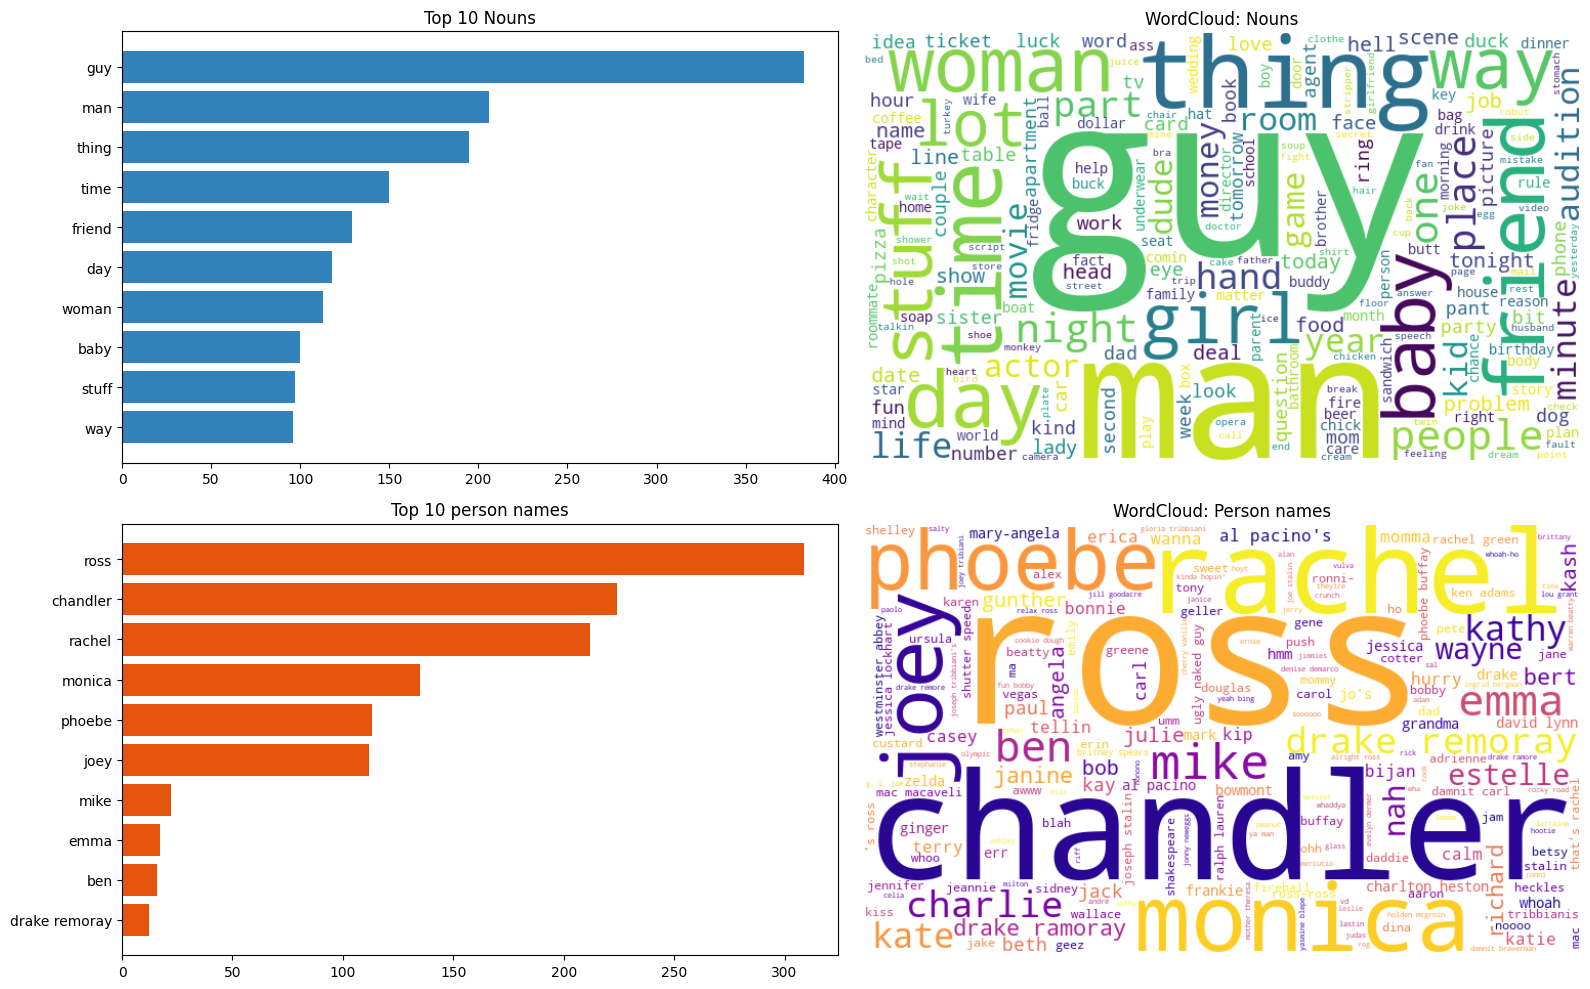

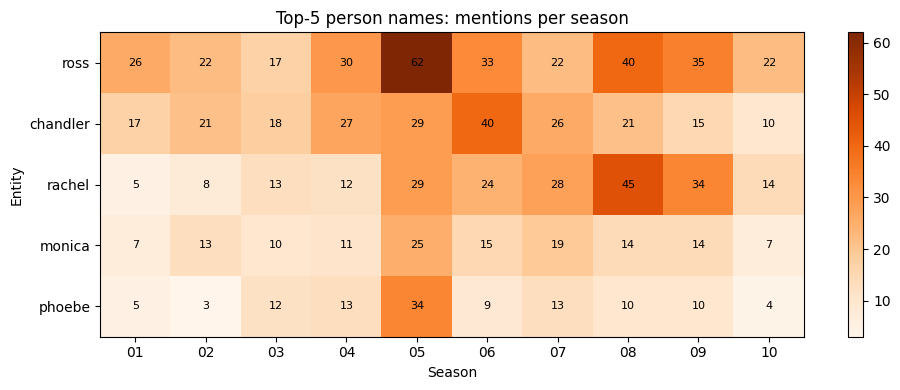

In [5]:
# init spaCy pipeline
nlp = spacy.load("en_core_web_sm")

# add EntityRuler 
ruler = nlp.add_pipe("entity_ruler", before="ner")
patterns = [
    {"label": "LOC",    "pattern": "Central Perk"},
    {"label": "PERSON", "pattern": "Chan-Chan Man"},
    {"label": "PERSON", "pattern": "Pheebs"},
    {"label": "PERSON", "pattern": "Rach"},
    {"label": "PERSON", "pattern": "Mon"}
]
ruler.add_patterns(patterns)

# noise sets
NOT_NOUNS = {"thank", "ohh", "ooh", "whoa", "huh", "hmm", "ah", "yeah"}
NON_PERSON = {"dude", "man", "guys", "guy", "kinda", "mornin", "alright", "congratulations","y'know","ya"}

joey2 = df_raw[df_raw["Speaker"].fillna("").str.strip().str.lower() == "joey"].copy()
joey2["clean_line"] = joey2["Text"].apply(strip_stage_directions)
joey2 = joey2[joey2["clean_line"] != ""].reset_index(drop=True)

docs = list(nlp.pipe(joey2["clean_line"], batch_size=250, disable=["parser"]))

# extract nouns and ners
nouns, entities_all = [], []

for season_label, doc in zip(joey2["Season"], docs):
    for tok in doc:
        if tok.pos_ == "NOUN" and tok.is_alpha:
            lem = tok.lemma_.lower()
            if lem not in nltk_stopwords and lem not in NOT_NOUNS and len(lem) > 1:
                nouns.append((season_label, lem))
    
    for ent in doc.ents:
        if ent.label_ in {"PERSON"}:
            clean_ent = ent.text.strip().lower()
            if clean_ent not in NON_PERSON and len(clean_ent) > 1:
                # apply alias map
                canonical = name_alias_map.get(clean_ent, clean_ent)
                entities_all.append((season_label, canonical, ent.label_))

# aggregate frequencies
noun_counts = Counter(lem for _, lem in nouns)
ent_counts = Counter(ent for _, ent, _ in entities_all)

print(f"Total Nouns extracted: {len(nouns)} ({len(noun_counts)} unique)")
print(f"Total person names extracted: {len(entities_all)} ({len(ent_counts)} unique)")
print("Top 7 Nouns:", noun_counts.most_common(7))
print("Top 7 person names:", ent_counts.most_common(7))

fig, ax = plt.subplots(2, 2, figsize=(16, 10))

top_nouns = pd.DataFrame(noun_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[0, 0].barh(top_nouns["w"], top_nouns["n"], color="#3182bd")
ax[0, 0].set_title("Top 10 Nouns")
wc_nouns = WordCloud(width=700, height=420, background_color="white", colormap="viridis").generate_from_frequencies(noun_counts)
ax[0, 1].imshow(wc_nouns, interpolation="bilinear")
ax[0, 1].axis("off")
ax[0, 1].set_title("WordCloud: Nouns")

top_ents = pd.DataFrame(ent_counts.most_common(10), columns=["w", "n"]).sort_values("n")
ax[1, 0].barh(top_ents["w"], top_ents["n"], color="#e6550d")
ax[1, 0].set_title("Top 10 person names")
wc_ents = WordCloud(width=700, height=420, background_color="white", colormap="plasma").generate_from_frequencies(ent_counts)
ax[1, 1].imshow(wc_ents, interpolation="bilinear")
ax[1, 1].axis("off")
ax[1, 1].set_title("WordCloud: Person names")

plt.tight_layout()
plt.show()


top_entities = [ent for ent, _ in ent_counts.most_common(5)]
season_series = pd.Series([s for s, _, _ in entities_all], name="season")
entity_series = pd.Series([e for _, e, _ in entities_all], name="entity")
heat_ent = pd.crosstab(entity_series, season_series).reindex(top_entities).fillna(0)
plt.figure(figsize=(10, 4))
plt.imshow(heat_ent.values, cmap="Oranges", aspect="auto")
plt.xticks(range(heat_ent.shape[1]), [c[-2:] for c in heat_ent.columns])  # Extracts S01, S02... format
plt.yticks(range(heat_ent.shape[0]), heat_ent.index)
for i in range(heat_ent.shape[0]):
    for j in range(heat_ent.shape[1]): plt.text(j, i, int(heat_ent.values[i, j]), ha="center", va="center", fontsize=8)

plt.xlabel("Season")
plt.ylabel("Entity")
plt.title("Top-5 person names: mentions per season")
plt.colorbar()
plt.tight_layout()
plt.show()

**Nouns: 9,566 mentions (2,047 distinct nouns)** Most frequent: guy (383), man (206), thing (195), time (150), friend (129), day (118), woman (113). The top nouns are informal, colloquial words (guy, man, thing), typical of casual dialogue

**Person names: 1,858 mentions (437 distinct names)** Most frequent: ross (309), chandler (224), rachel (212), monica (135), phoebe (113), joey (112), mike (22)
- Ross, Chandler and Rachel together make up 745 of the 1,858 mentions (40%). The six main characters together make up 1,105 (59%) and the other ~750 mentions are spread over about 430 other names.
- Joey mentions Ross most, followed by Chandler and Rachel
- Outside the main six, Mike(Phoebe's boyfriend and later husband) is the most mentioned person

**Per season (heatmap; raw counts)** Ross (62), Monica (25) and Phoebe (34) are mentioned most in Season 5, Chandler (40) in Season 6 and Rachel (45) in Season 8. Summed over the five names, Season 5 is highest (179 mentions), then Season 8 (130). 

### Q3. Most important words: per episode, per season, overall

1. `q3_tokens`: strip stage directions, expand contractions, lower-case, tokenise, keep alphabetic tokens only, map aliases, and remove stopwords 
2. Take Joey's lines, derive Porter stems, and build a dictionary that maps each stem back to its most frequent original word
3. Group the stems into one document per episode and one per season
4. Build bag-of-words count matrices and compute TF-IDF with `TfidfTransformer`
5. **Overall:** total bag-of-words counts over all episodes, with and without the six main names 
6. **Per season:** TF-IDF with the 10 seasons as documents with words used in more than 7 seasons ignored to see what is *specific* to a season
7. **Per episode:** TF-IDF with the episodes as documents with words that occur in more than half of the episodes ignored

In [6]:
MAIN = {"ross", "rachel", "monica", "chandler", "phoebe", "joey"}

# lower case, no stage directions, contractions expanded
def q3_tokens(text):
    t = expand_contractions(strip_stage_directions(text))                                    
    toks = [name_alias_map.get(w, w) for w in word_tokenize(t) if w.isalpha()]              
    return [w for w in toks if len(w) > 2 and w not in custom_stopwords]

joey3 = df_raw[df_raw["Speaker"].fillna("").str.strip().str.lower() == "joey"].copy()
joey3["tokens"] = joey3["Text"].apply(q3_tokens)
joey3["stems"] = joey3["tokens"].apply(lambda ts: [stemmer.stem(w) for w in ts])
stem2lexeme = stem_to_lexeme_mapper([s for ss in joey3["stems"] for s in ss], [w for ts in joey3["tokens"] for w in ts])   

def make_docs(by):
    d = joey3.groupby(by)["stems"].apply(lambda x: " ".join(" ".join(s) for s in x)).reset_index().rename(columns={"stems": "text"})
    d["season_num"] = d["Season"].str.extract(r"(\d+)")[0].astype(int)
    if "Episode" in by: d["ep_num"] = d["Episode"].str.extract(r"(\d+)")[0].astype(int)
    return d.sort_values(["season_num"] + (["ep_num"] if "Episode" in by else [])).reset_index(drop=True)

def importance(texts, min_total=3, max_df=1.0, sublinear=True):
    bow = CountVectorizer(token_pattern=r"\S+").fit(texts); feats = np.array(bow.get_feature_names_out()); X = bow.transform(texts)
    doc_share = np.asarray((X > 0).sum(0)).ravel() / X.shape[0]
    keep = (np.asarray(X.sum(0)).ravel() >= min_total) & (doc_share <= max_df)
    X, feats = X[:, keep], feats[keep]
    return X, TfidfTransformer(sublinear_tf=sublinear).fit_transform(X), np.array([stem2lexeme.get(s, s) for s in feats])

def top_words(row, lex, k):
    row = np.asarray(row).ravel(); idx = np.argsort(row)[::-1][:k]; return [(lex[i], row[i]) for i in idx if row[i] > 0]

ep_docs = make_docs(["Season", "Episode"]); season_docs = make_docs(["Season"])

# bag-of-words counts 
X_all, _, lex_all = importance(ep_docs["text"], min_total=1)
counts_all = pd.Series(np.asarray(X_all.sum(0)).ravel(), index=lex_all).groupby(level=0).sum().sort_values(ascending=False)
no_main = counts_all[~counts_all.index.isin(MAIN)]
print("10 most frequent words\n", pd.DataFrame({"all words": counts_all.head(10).index, "count": counts_all.head(10).values,
      "without the 6 main chars": no_main.head(10).index, "count ": no_main.head(10).values}).to_string(index=False))

# per season: TF-IDF with the 10 seasons as documents 
Xs, Ts, lex_s = importance(season_docs["text"], min_total=5, max_df=0.7)
season_top = {s: top_words(Ts[i].toarray(), lex_s, 8) for i, s in enumerate(season_docs["Season"])}
print("\nPER SEASON - top 8 TF-IDF words (words used in more than 7 seasons are ignored)")
print(pd.DataFrame({"Season": list(season_top), "top words": [", ".join(w for w, _ in v) for v in season_top.values()]}).to_string(index=False))

# per season, raw frequency view (BoW)
Xs1, _, lex_s1 = importance(season_docs["text"], min_total=1)
print("\nPER SEASON - 5 most frequent words (BoW)")
print(pd.DataFrame({"Season": season_docs["Season"], "top words": [", ".join(lex_s1[np.argsort(np.asarray(Xs1[i].todense()).ravel())[::-1][:5]]) for i in range(len(season_docs))]}).to_string(index=False))

# per episode: TF-IDF 
Xe, Te, lex_e = importance(ep_docs["text"], min_total=3, max_df=0.5)
ep_table = pd.DataFrame({"Season": ep_docs["Season"], "Episode Name": ep_docs["Episode"],"top 5 words (TF-IDF)": [", ".join(w for w, _ in top_words(Te[i].toarray(), lex_e, 5)) for i in range(len(ep_docs))]})
with pd.option_context("display.max_rows", None, "display.max_colwidth", 100, "display.width", 250): display(ep_table)

10 most frequent words
 all words  count without the 6 main chars  count 
     ross    323                     good     268
     good    268                    great     190
   rachel    231                   little     167
 chandler    230                     talk     166
   phoebe    202                   thanks     165
    great    190                    sorry     157
   little    167                     time     155
     talk    166                   listen     140
   thanks    165                    maybe     136
     joey    163                   friend     128

PER SEASON - top 8 TF-IDF words (words used in more than 7 seasons are ignored)
   Season                                                           top words
Season-01            stalin, ursula, bob, marcel, pacino, angela, order, paul
Season-02 peeking, elevator, willing, bracelet, juice, julie, copier, panties
Season-03          kate, opposite, beth, janice, blank, trees, window, lauren
Season-04       kathy, stripper, 

,Season,Episode Name,top 5 words (TF-IDF)
0,Season-01,Episode-01-The One Where Monica Gets a New Roommate (The Pilot),"paul, cream, date, real, line"
1,Season-01,Episode-02-The One With the Sonogram at the End,"folks, slow, calm, ruin, still"
2,Season-01,Episode-03-The One With the Thumb,"whoah, respect, ridiculous, smoke, keep"
3,Season-01,Episode-04-The One With George Stephanopoulos,"hockey, carol, sit, slept, boy"
4,Season-01,Episode-05-The One With the East German Laundry Detergent,"bob, angela, mississippi, brother, together"
5,Season-01,Episode-06-The One With the Butt,"pacino, butt, robe, agency, order"
6,Season-01,Episode-07-The One With the Blackout,"zone, candles, party, everyone, library"
7,Season-01,Episode-08-The One Where Nana Dies Twice,"dead, worm, twice, giant, third"
8,Season-01,Episode-09-The One where Underdog Gets Away,"aramis, keys, family, wait, entirely"
9,Season-01,Episode-10-The One With the Monkey,"sandy, bobby, store, kids, slap"


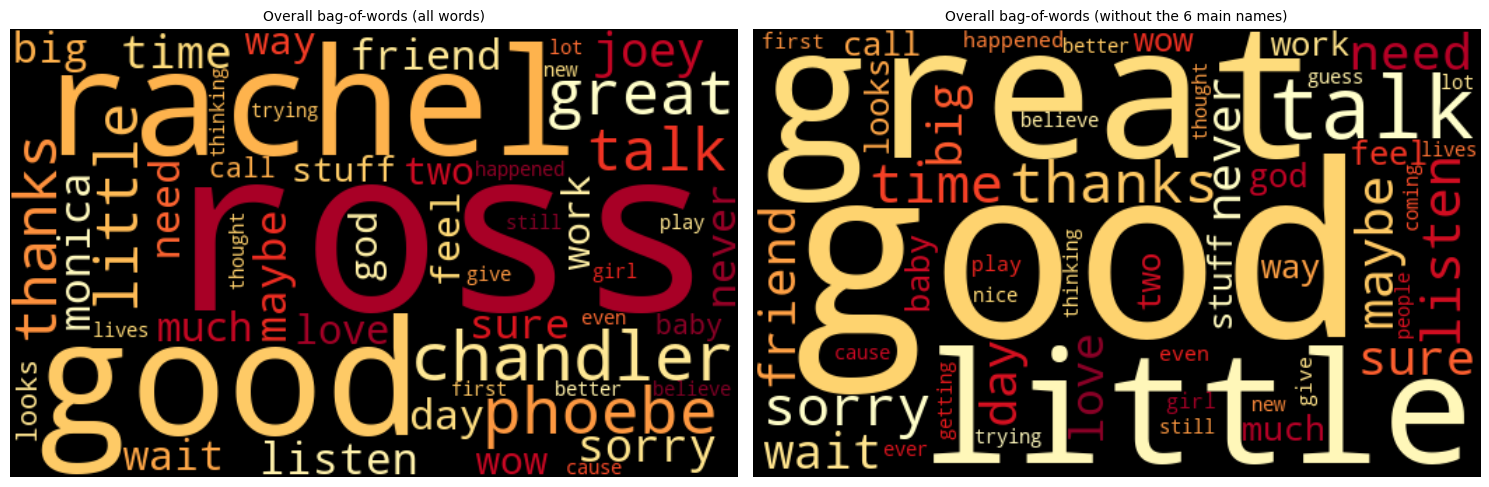

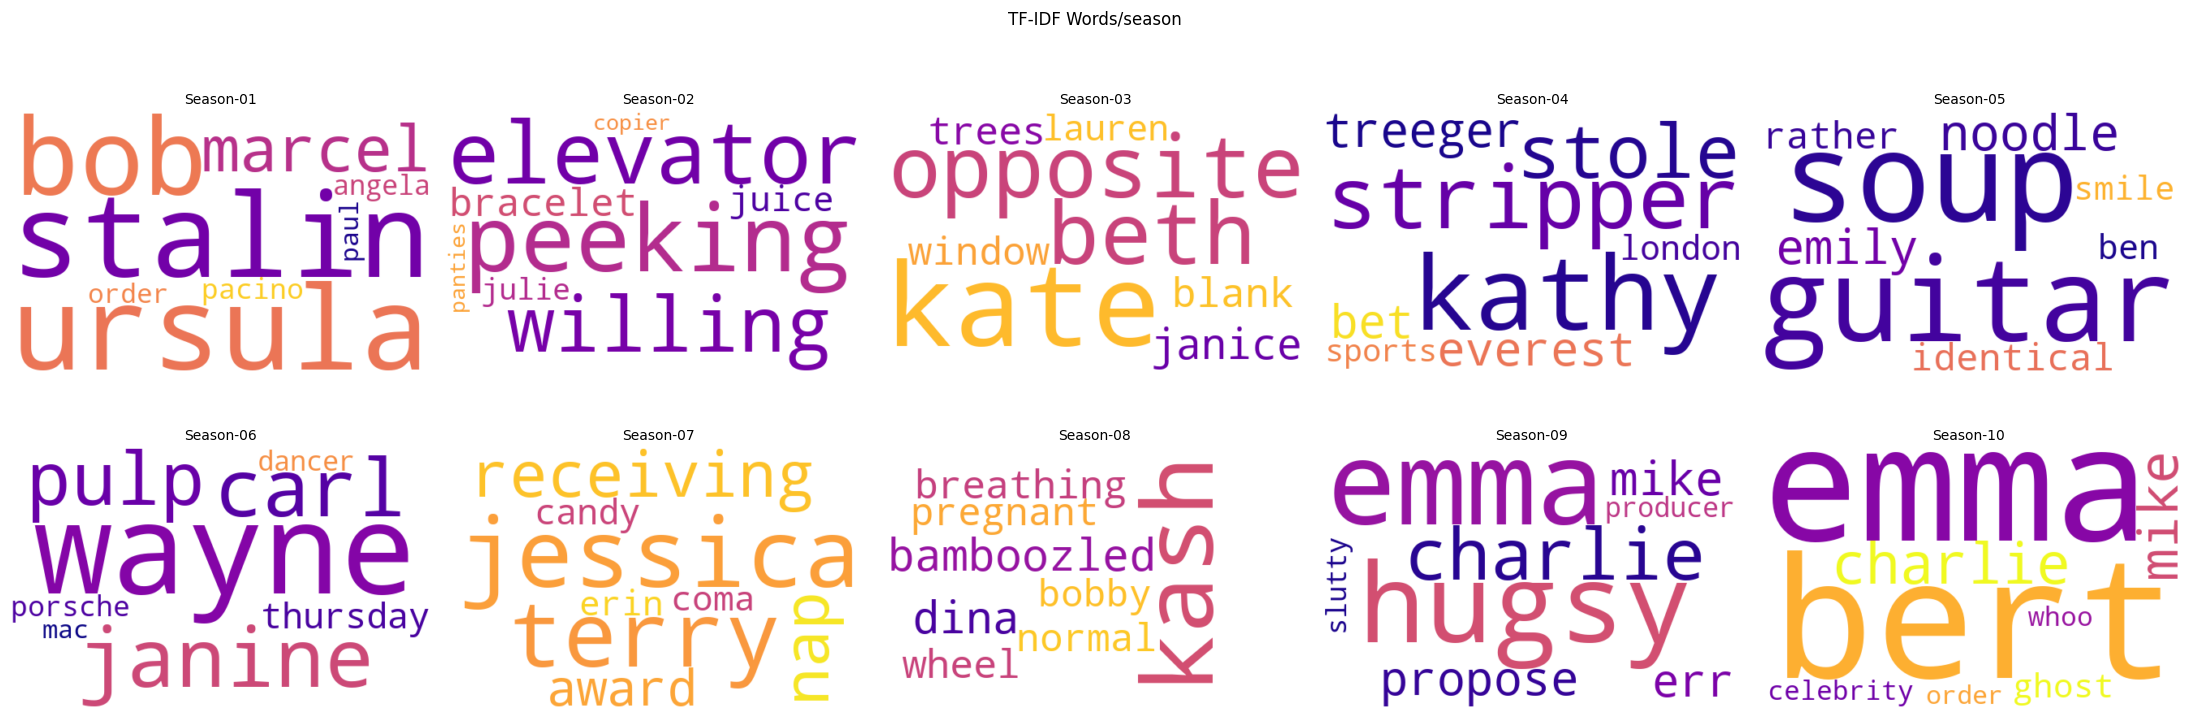

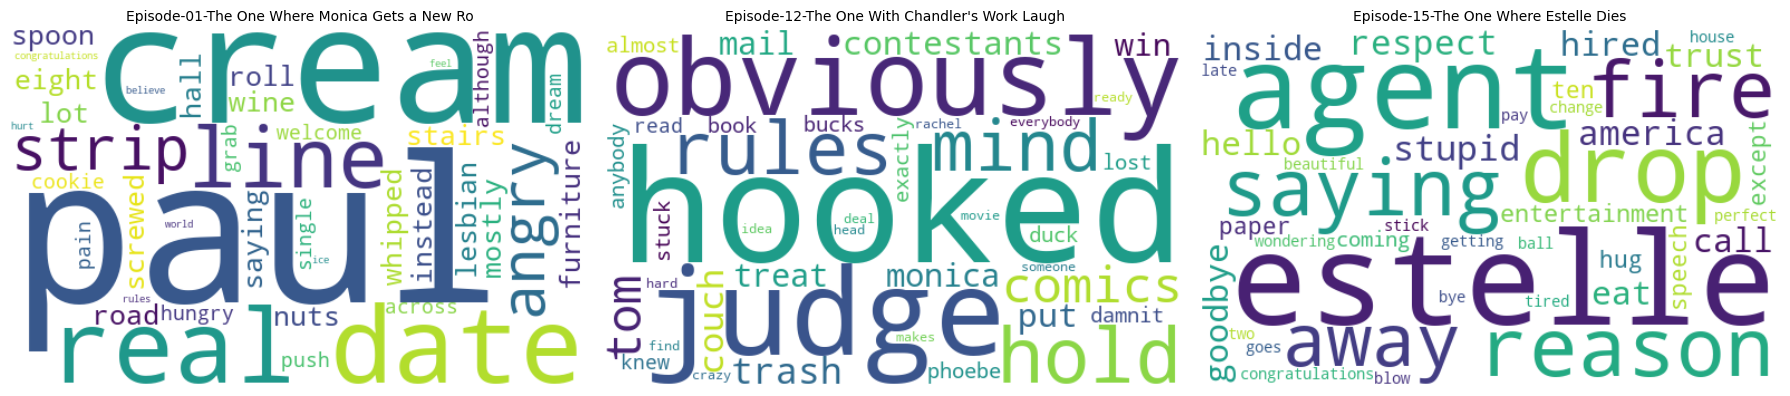

In [7]:
def cloud(ax, freq, title, cmap="viridis", bg="white"):
    wc = WordCloud(width=520, height=320, background_color=bg, colormap=cmap, max_words=50).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); 
    ax.axis("off"); 
    ax.set_title(title, fontsize=10)

# overall cloud - with and without char names
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
cloud(ax[0], counts_all.head(80).to_dict(), "Overall bag-of-words (all words)", "YlOrRd", "black")
cloud(ax[1], no_main.head(80).to_dict(), "Overall bag-of-words (without the 6 main names)", "YlOrRd", "black")
plt.tight_layout(); 
plt.show()

# one cloud per season (TF-IDF scores)
fig, ax = plt.subplots(2, 5, figsize=(22, 8))
for a, (s, v) in zip(ax.ravel(), season_top.items()): cloud(a, {w: sc for w, sc in v}, s, "plasma")
plt.suptitle("TF-IDF Words/season"); 
plt.tight_layout(); 
plt.show()

# episode cloud
def episode_cloud(season_num, ep_num, ax=None):
    i = ep_docs.index[(ep_docs.season_num == season_num) & (ep_docs.ep_num == ep_num)][0]
    f = {w: sc for w, sc in top_words(Te[i].toarray(), lex_e, 40)}
    if ax is None: fig, ax = plt.subplots(figsize=(6, 4))
    cloud(ax, f, ep_docs.loc[i, "Episode"][:45], "viridis")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, (s, e) in zip(ax, [(1, 1), (5, 12), (10, 15)]): episode_cloud(s, e, a)      
plt.tight_layout(); 
plt.show()

**Overall (bag-of-words = most frequent words)** The ten most frequent words are ross (323), good (268), rachel (231), chandler (230), phoebe (202), great (190), little (167), talk (166), thanks (165) and joey (163). The friends' names dominate because Joey talks to and about them and the other top words are generic, polite or reactive words (good, great, thanks, sorry). 

**Per season, bag-of-words** The raw top-5 lists are very similar across seasons (names plus generic words), so frequency does not separate the seasons well. Chandler is in the top 5 of Seasons 1–7 but not of Seasons 8–10, and Rachel enters from Season 5 on (Seasons 5 and 7–10), which matches the earlier heatmap

**Per season, TF-IDF** -tied to a season's storylines:
- S1: stalin, ursula, bob, marcel, pacino (Marcel is Ross's monkey, Ursula is Phoebe's twin)
- S3: janice (Chandler's girlfriend)
- S5: emily (Ross's wife), soup, guitar
- S6: wayne, janine, porsche
- S8: pregnant, kash, dina
- S9: emma (Rachel's baby), hugsy (Joey's stuffed penguin), mike, charlie, propose
- S10: bert, emma, charlie, mike, ghost

**Per episode, TF-IDF** Episode-level TF-IDF often isolates the plot of the episode. For example, S1E06 "The One With the Butt" gives pacino, butt, robe, agency, S1E19 "The One Where the Monkey Gets Away" gives marcel, monkey

- Joey has relatively few lines in early seasons, so some episode lists are noisy or generic (S1E02: folks, slow, calm, ruin, still).
- Some interjections pass through (uhhhh, ahhh, whoah, whoo, heh, wha, err).

**Which words are typical for Joey compared with the other main characters?**
1. Build one document per character from the same stemmed and cleaned tokens.
2. Compute TF-IDF over the six documents, dropping words used by more than 3 of the 6 characters and words with fewer than 5 occurrences 
3. Print highest TF-IDF score words for Joey.

In [8]:
MAIN_SPEAKERS = ["rachel", "ross", "monica", "chandler", "joey", "phoebe"]
spk_all = df_raw["Speaker"].fillna("").str.strip().str.lower()
char_docs = {c: " ".join(" ".join(stemmer.stem(w) for w in q3_tokens(t)) for t in df_raw.loc[spk_all == c, "Text"]) for c in MAIN_SPEAKERS}
Xc, Tc, lex_c = importance(list(char_docs.values()), min_total=5, max_df=0.5)       
joey_i = MAIN_SPEAKERS.index("joey")
print("Typical Joey Words (TF-IDF, characters as documents):", [w for w, _ in top_words(Tc[joey_i].toarray(), lex_c, 20)])

Typical Joey Words (TF-IDF, characters as documents): ['script', 'wayne', 'estelle', 'neurosurgeon', 'blank', 'hugsy', 'dorks', 'shaft', 'ramoray', 'remoray', 'kash', 'angela', 'pacino', 'kate', 'casting', 'clinic', 'pulp', 'err', 'stalin', 'copier']


**Joey's vocabulary** - script, wayne, estelle, neurosurgeon, blank, hugsy, dorks, shaft, ramoray, remoray, kash, angela, pacino, kate, casting, clinic, pulp, err, stalin, copier.
- About a third relate to acting: script, estelle(his agent), neurosurgeon,ramoray/remoray(Dr. Drake Ramoray from Days of Our Lives), and pacino.
- Several are names that also appear in the season TF-IDF lists

### Q4. Co-occurrence of words with PPMI

1. Use the same tokens as Q3 but **not stemmed** 
2. Count word frequencies and keep words that occur at least 10 times
3. Slide a window of 5 tokens on each side over every line and add 1 to the symmetric count of each pair
4. Compute joint and marginal probabilities
5. PMI = log2( p(x,y) / (p(x) p(y)) ) with pairs that occur fewer than 5 times being set to 0
6. Take the upper triangle of the symmetric matrix 
7. Visualise via plots

In [9]:
# same tokens as Q3 (stage directions removed, contractions expanded, stopwords removed), NOT stemmed
joey4_tokens = joey3["tokens"]            

def compute_ppmi(token_series, window=5, min_word_freq=10, min_pair_freq=5, alpha=1.0):
    counts = Counter(w for toks in token_series for w in toks)
    vocab = [w for w, c in counts.items() if c >= min_word_freq]; w2i = {w: i for i, w in enumerate(vocab)}; V = len(vocab)
    co = np.zeros((V, V))
    for toks in token_series:                                         
        ids = [w2i[w] for w in toks if w in w2i]                      
        for k, i in enumerate(ids):
            for c in range(max(0, k - window), min(len(ids), k + window + 1)):
                if c != k and ids[c] != i: co[i, ids[c]] += 1        
    total = co.sum(); p_xy = co / total; p_x = co.sum(1) / total      
    ctx = co.sum(0) ** alpha; p_y = ctx / ctx.sum()                  
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log2(p_xy / np.outer(p_x, p_y))
    pmi[~np.isfinite(pmi)] = 0
    ppmi = np.maximum(pmi, 0)                                       
    ppmi[co < min_pair_freq] = 0                                     
    return pd.DataFrame(ppmi, index=vocab, columns=vocab), pd.DataFrame(co, index=vocab, columns=vocab)

def top_pairs(ppmi, co, k=15, by="PPMI"):
    P, C = ppmi.values, co.values; iu = np.triu_indices(len(P), 1)
    s = P[iu] if by == "PPMI" else np.where(P[iu] > 0, C[iu], 0)      
    o = np.argsort(s)[::-1][:k]
    return pd.DataFrame({"word 1": ppmi.index[iu[0][o]], "word 2": ppmi.index[iu[1][o]], "PPMI": P[iu][o].round(2), "count": C[iu][o].astype(int)})

ppmi4, co4 = compute_ppmi(joey4_tokens)
print(f"vocabulary: {len(ppmi4)} words (frequency >= 10), pairs with PPMI > 0 and count >= 5: {int(np.triu(ppmi4.values > 0, 1).sum())}")
print("\nStrongest associations (PPMI), pair count >= 5"); display(top_pairs(ppmi4, co4, 10, "PPMI"))
print("Most frequent word pairs that are positively associated"); display(top_pairs(ppmi4, co4, 10, "count"))

vocabulary: 529 words (frequency >= 10), pairs with PPMI > 0 and count >= 5: 432

Strongest associations (PPMI), pair count >= 5


,word 1,word 2,PPMI,count
0,lose,bet,8.37,10
1,keys,porsche,8.17,10
2,lying,lie,7.86,7
3,chick,duck,7.82,6
4,hugsy,emma,7.56,7
5,push,ball,7.55,6
6,tickets,knicks,7.43,6
7,five,hundred,7.27,10
8,high,school,7.09,7
9,york,city,7.03,8


Most frequent word pairs that are positively associated


,word 1,word 2,PPMI,count
0,wait,minute,5.49,44
1,ross,rachel,1.71,40
2,lives,days,6.02,30
3,chandler,monica,2.51,28
4,big,deal,4.72,28
5,ross,chandler,0.89,22
6,last,night,4.25,21
7,good,luck,4.21,18
8,rachel,friend,2.26,17
9,little,bit,4.73,16


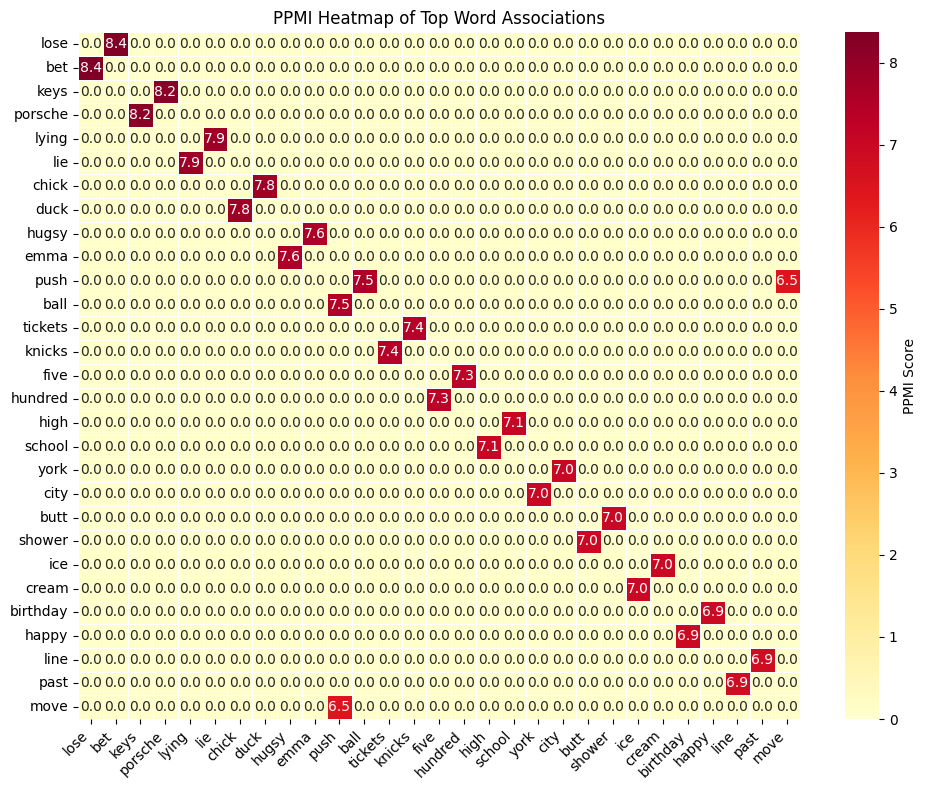

In [10]:
tp = top_pairs(ppmi4, co4, 15, "PPMI")
words = list(dict.fromkeys(tp[["word 1", "word 2"]].values.ravel()))
M_df = ppmi4.loc[words, words]

plt.figure(figsize=(10, 8))
sns.heatmap(M_df, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'PPMI Score'}, linewidths=0.5)
plt.title("PPMI Heatmap of Top Word Associations", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
def where(w1, w2):
    m = joey3["tokens"].apply(lambda t: w1 in t and w2 in t)
    return joey3.loc[m, ["Season","Episode","Text"]].head(5)
where("keys", "porsche")

,Season,Episode,Text
36634,Season-06,Episode-05-The One With Joey’s Porsche,"Oh! Hey, somebody left their keys. (Looks at ..."
36702,Season-06,Episode-05-The One With Joey’s Porsche,"Hey babies! Oh, I’m having the best morning. ..."


529 words occur at least 10 times and 432 word pairs have PPMI > 0 and at least 5 co-occurrences. A PPMI of about 7 to 8 means that the pair occurs together roughly 130 to 330 times more often than expected by chance. PPMI favours rare words, so even with the minimum of 5 co-occurrences the strongest pairs rest on few observations (6 to 10)

**Strongest associations (PPMI)**
- *Fixed expressions:* five–hundred (7.27), high–school (7.09), york–city (7.03)
- *Storyline pairs:* lose–bet (8.37; bet is a distinctive Season 4 word), keys–porsche (8.17; S6E5 "The One With Joey's Porsche"), hugsy–emma (7.56 top Season 9 words), tickets–knicks (7.43)

**Most frequent positively associated pairs**
- *Fixed expressions:* wait–minute (44; PPMI 5.49), big–deal (28), last–night (21), good–luck (18), little–bit (16).
- *lives–days* (30; PPMI 6.02): *Days of Our Lives*, Joey's soap opera
- *Pairs of friends:* ross–rachel (40), chandler–monica (28), ross–chandler (22) and rachel–friend (17)

**Overall** Joey's most strongly associated words are mostly fixed English expressions plus a handful of storyline-specific pairs. Frequent co-occurrence (counts) and strong association (PPMI) pick out different pairs